# University Student Stressors Questionnaire (USSQ) — Initial EDA

**Dataset:** University Student Stressors Questionnaire (USSQ): Validation Dataset  
**Source:** https://zenodo.org/records/20529873

This notebook performs the initial Exploratory Data Analysis (EDA) required for the project.

The dataset contains:
- 29 USSQ academic-stressor items (`EU1`–`EU29`)
- Demographic variables
- DASS-21 subscale and total scores
- Six Ryff Psychological Well-Being dimensions

> **Note:** This notebook is for initial EDA only. Machine-learning preprocessing, feature selection, train/test splitting, baseline model development, and SHAP analysis will be performed in later stages.

# 1. INSTALL MISSING LIBRARIES

In [63]:
!pip -q install xgboost catboost lightgbm shap openpyxl

## 2. Import Libraries

In [64]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    VotingRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

import shap

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


# 3. Load dataset

In [65]:
print("\n📊 Loading Dataset...")

file_link = (
    'https://drive.google.com/file/d/'
    '1i7yj88_ruLnasOndgSricLI8uVCR-cpU/'
    'view?usp=drive_link'
)

file_id = file_link.split("/")[-2]

new_link = f'https://drive.google.com/uc?id={file_id}'

print("Google Drive direct link:")
print(new_link)

try:

    df = pd.read_csv(new_link)

    print("\n✅ Dataset loaded successfully!")

    print(f"   Shape: {df.shape}")
    print(f"   Participants: {len(df):,}")
    print(f"   Variables: {len(df.columns)}")

except Exception as e:

    print("\n❌ Error loading dataset:")
    print(e)

    raise


📊 Loading Dataset...
Google Drive direct link:
https://drive.google.com/uc?id=1i7yj88_ruLnasOndgSricLI8uVCR-cpU

✅ Dataset loaded successfully!
   Shape: (4925, 45)
   Participants: 4,925
   Variables: 45


# 4. Basic dataset inspection

In [66]:
print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

DATASET INFORMATION
Rows: 4925
Columns: 45

Column names:
['Unnamed: 0', 'sexo_bio', 'id_genero', 'edad', 'study_level', 'facultad', 'EU1', 'EU2', 'EU3', 'EU4', 'EU5', 'EU6', 'EU7', 'EU8', 'EU9', 'EU10', 'EU11', 'EU12', 'EU13', 'EU14', 'EU15', 'EU16', 'EU17', 'EU18', 'EU19', 'EU20', 'EU21', 'EU22', 'EU23', 'EU24', 'EU25', 'EU26', 'EU27', 'EU28', 'EU29', 'DASS_D', 'DASS_A', 'DASS_S', 'DASS_total', 'PWB_sel', 'PWB_pos', 'PWB_aut', 'PWB_env', 'PWB_pur', 'PWB_per']

Data types:


,0
Unnamed: 0,int64
sexo_bio,object
id_genero,object
edad,int64
study_level,object
facultad,object
EU1,int64
EU2,int64
EU3,int64
EU4,int64



First 5 rows:


,Unnamed: 0,sexo_bio,id_genero,edad,study_level,facultad,EU1,EU2,EU3,EU4,...,DASS_D,DASS_A,DASS_S,DASS_total,PWB_sel,PWB_pos,PWB_aut,PWB_env,PWB_pur,PWB_per
0,1,Mujer,Mujer,20,undergraduate,Facultad de Ciencias Jurídicas,2,2,3,4,...,0,2,0,4,32,32,38,28,42,27
1,2,Hombre,Hombre,19,undergraduate,"ETS de Ingeniería Industrial, Informática y de...",2,2,3,1,...,0,0,1,2,33,37,31,35,36,24
2,3,Mujer,Mujer,20,undergraduate,"Facultad de Ciencias Humanas, Sociales y de la...",2,3,4,2,...,15,17,17,98,29,33,32,33,26,19
3,4,Hombre,Hombre,20,undergraduate,"Facultad de Ciencias Humanas, Sociales y de la...",2,2,3,2,...,4,3,4,22,11,13,23,19,18,17
4,5,Mujer,Mujer,21,postgraduate,"Facultad de Ciencias Humanas, Sociales y de la...",1,1,2,2,...,0,0,1,2,42,42,31,37,32,42


# 5. Data quality analysis

In [67]:
print("=" * 70)
print("DATA QUALITY ANALYSIS")
print("=" * 70)

# Missing values
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df)) * 100
})

display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        "Missing_Count",
        ascending=False
    )
)

print("Total missing cells:", df.isnull().sum().sum())

# Duplicate rows
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

# Unique values
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [
        df[col].nunique(dropna=True)
        for col in df.columns
    ]
})

display(unique_summary)

DATA QUALITY ANALYSIS


,Missing_Count,Missing_Percentage


Total missing cells: 0
Duplicate rows: 0


,Column,Unique_Values
0,Unnamed: 0,4925
1,sexo_bio,3
2,id_genero,3
3,edad,38
4,study_level,2
5,facultad,7
6,EU1,4
7,EU2,4
8,EU3,4
9,EU4,4


# 6. Identify USSQ items

In [68]:
ussq_items = [
    f"EU{i}" for i in range(1, 30)
]

ussq_features = [f"EU{i}" for i in range(1, 30)]

available_ussq = [
    col for col in ussq_items
    if col in df.columns
]

missing_ussq = [
    col for col in ussq_items
    if col not in df.columns
]

print("USSQ items found:", len(available_ussq))
print(available_ussq)

if missing_ussq:
    print("\nWARNING - Missing USSQ columns:")
    print(missing_ussq)

USSQ items found: 29
['EU1', 'EU2', 'EU3', 'EU4', 'EU5', 'EU6', 'EU7', 'EU8', 'EU9', 'EU10', 'EU11', 'EU12', 'EU13', 'EU14', 'EU15', 'EU16', 'EU17', 'EU18', 'EU19', 'EU20', 'EU21', 'EU22', 'EU23', 'EU24', 'EU25', 'EU26', 'EU27', 'EU28', 'EU29']


# 7. Identify DASS and Ryff variables

In [69]:
dass_columns = [
    col for col in df.columns
    if col.upper().startswith("DASS")
]

ryff_columns = [
    col for col in df.columns
    if col.upper().startswith("PWB")
]

print("DASS variables:")
print(dass_columns)

print("\nRyff/PWB variables:")
print(ryff_columns)

DASS variables:
['DASS_D', 'DASS_A', 'DASS_S', 'DASS_total']

Ryff/PWB variables:
['PWB_sel', 'PWB_pos', 'PWB_aut', 'PWB_env', 'PWB_pur', 'PWB_per']


# 8. Demographic analysis

In [70]:
demographic_candidates = [
    "sexo_bio",
    "id_genero",
    "edad",
    "study_level",
    "facultad"
]

demographic_columns = [
    col for col in demographic_candidates
    if col in df.columns
]

print("Demographic variables:")
print(demographic_columns)

Demographic variables:
['sexo_bio', 'id_genero', 'edad', 'study_level', 'facultad']


# Gender

Biological Gender Distribution


,Count,Percentage
sexo_bio,,
Mujer,2951,59.918782
Hombre,1964,39.878173
Otro,10,0.203046


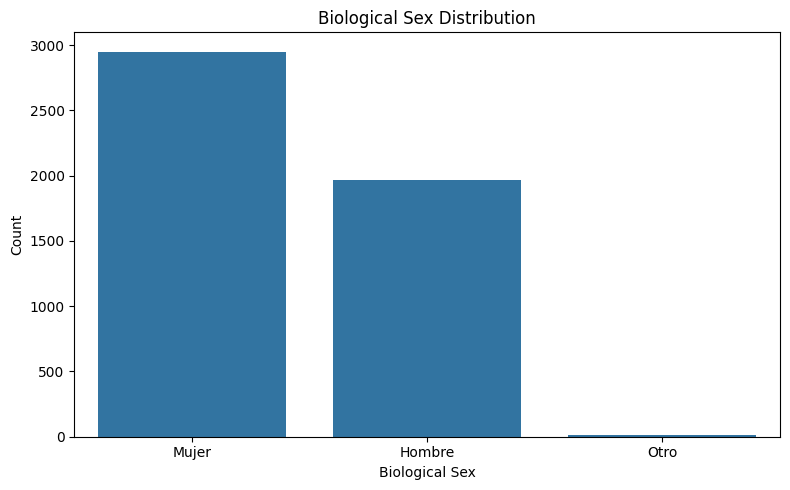

In [71]:
if "sexo_bio" in df.columns:

    print("Biological Gender Distribution")

    sex_counts = df["sexo_bio"].value_counts(dropna=False)

    display(
        pd.DataFrame({
            "Count": sex_counts,
            "Percentage": sex_counts / len(df) * 100
        })
    )

    plt.figure(figsize=(8,5))

    sns.countplot(
        data=df,
        x="sexo_bio"
    )

    plt.title("Biological Sex Distribution")
    plt.xlabel("Biological Sex")
    plt.ylabel("Count")

    plt.tight_layout()
    plt.show()

# 9. Study level


,Count,Percentage
study_level,,
undergraduate,4374,88.812183
postgraduate,551,11.187817


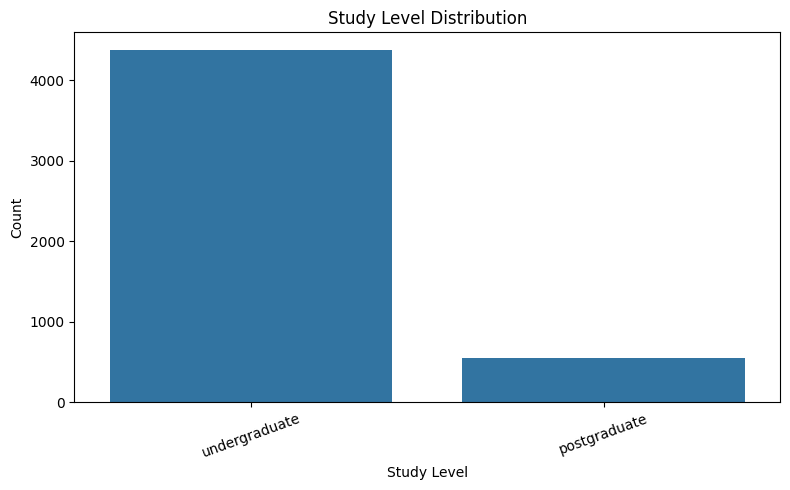

In [72]:
if "study_level" in df.columns:

    counts = df["study_level"].value_counts(dropna=False)

    display(
        pd.DataFrame({
            "Count": counts,
            "Percentage": counts / len(df) * 100
        })
    )

    plt.figure(figsize=(8,5))

    sns.countplot(
        data=df,
        x="study_level"
    )

    plt.title("Study Level Distribution")
    plt.xlabel("Study Level")
    plt.ylabel("Count")

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

# 10. Age analysis

Age statistics


,edad
count,4925.000000
mean,20.530964
std,3.507116
min,16.000000
25%,19.000000
50%,20.000000
75%,21.000000
max,65.000000


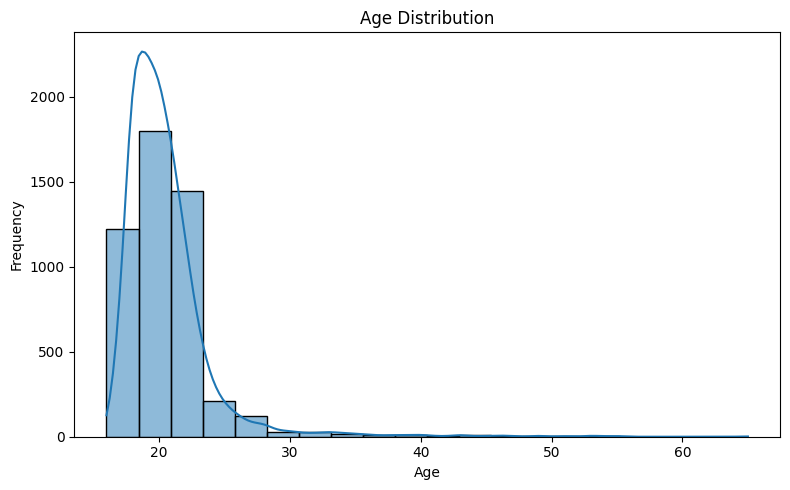

In [73]:
if "edad" in df.columns:

    print("Age statistics")

    display(
        df["edad"].describe()
    )

    plt.figure(figsize=(8,5))

    sns.histplot(
        df["edad"].dropna(),
        bins=20,
        kde=True
    )

    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

# 11. USSQ descriptive statistics

In [74]:
ussq_stats = df[available_ussq].describe().T

ussq_stats["Missing"] = df[available_ussq].isnull().sum()

display(ussq_stats)

,count,mean,std,min,25%,50%,75%,max,Missing
EU1,4925.0,1.980102,0.790383,1.0,1.0,2.0,2.0,4.0,0
EU2,4925.0,2.350051,0.893213,1.0,2.0,2.0,3.0,4.0,0
EU3,4925.0,2.442843,0.812319,1.0,2.0,2.0,3.0,4.0,0
EU4,4925.0,2.498477,0.902118,1.0,2.0,2.0,3.0,4.0,0
EU5,4925.0,2.015228,0.848358,1.0,1.0,2.0,3.0,4.0,0
EU6,4925.0,1.768934,0.943472,1.0,1.0,1.0,2.0,4.0,0
EU7,4925.0,1.932386,0.935630,1.0,1.0,2.0,3.0,4.0,0
EU8,4925.0,1.296853,0.638591,1.0,1.0,1.0,1.0,4.0,0
EU9,4925.0,1.733604,0.898651,1.0,1.0,1.0,2.0,4.0,0
EU10,4925.0,2.659492,1.045276,1.0,2.0,3.0,4.0,4.0,0


# 12. USSQ mean distribution

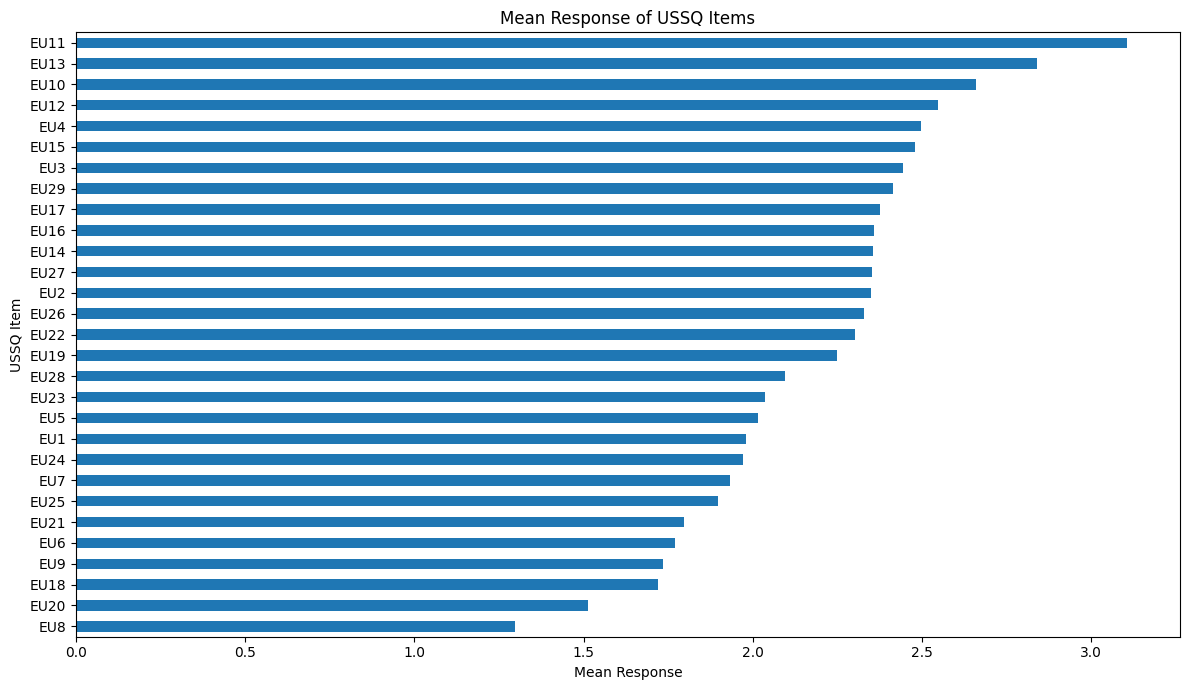

In [75]:
ussq_means = df[available_ussq].mean().sort_values()

plt.figure(figsize=(12,7))

ussq_means.plot(
    kind="barh"
)

plt.title("Mean Response of USSQ Items")
plt.xlabel("Mean Response")
plt.ylabel("USSQ Item")

plt.tight_layout()

plt.savefig(
    "ussq_means.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 13. USSQ item distributions

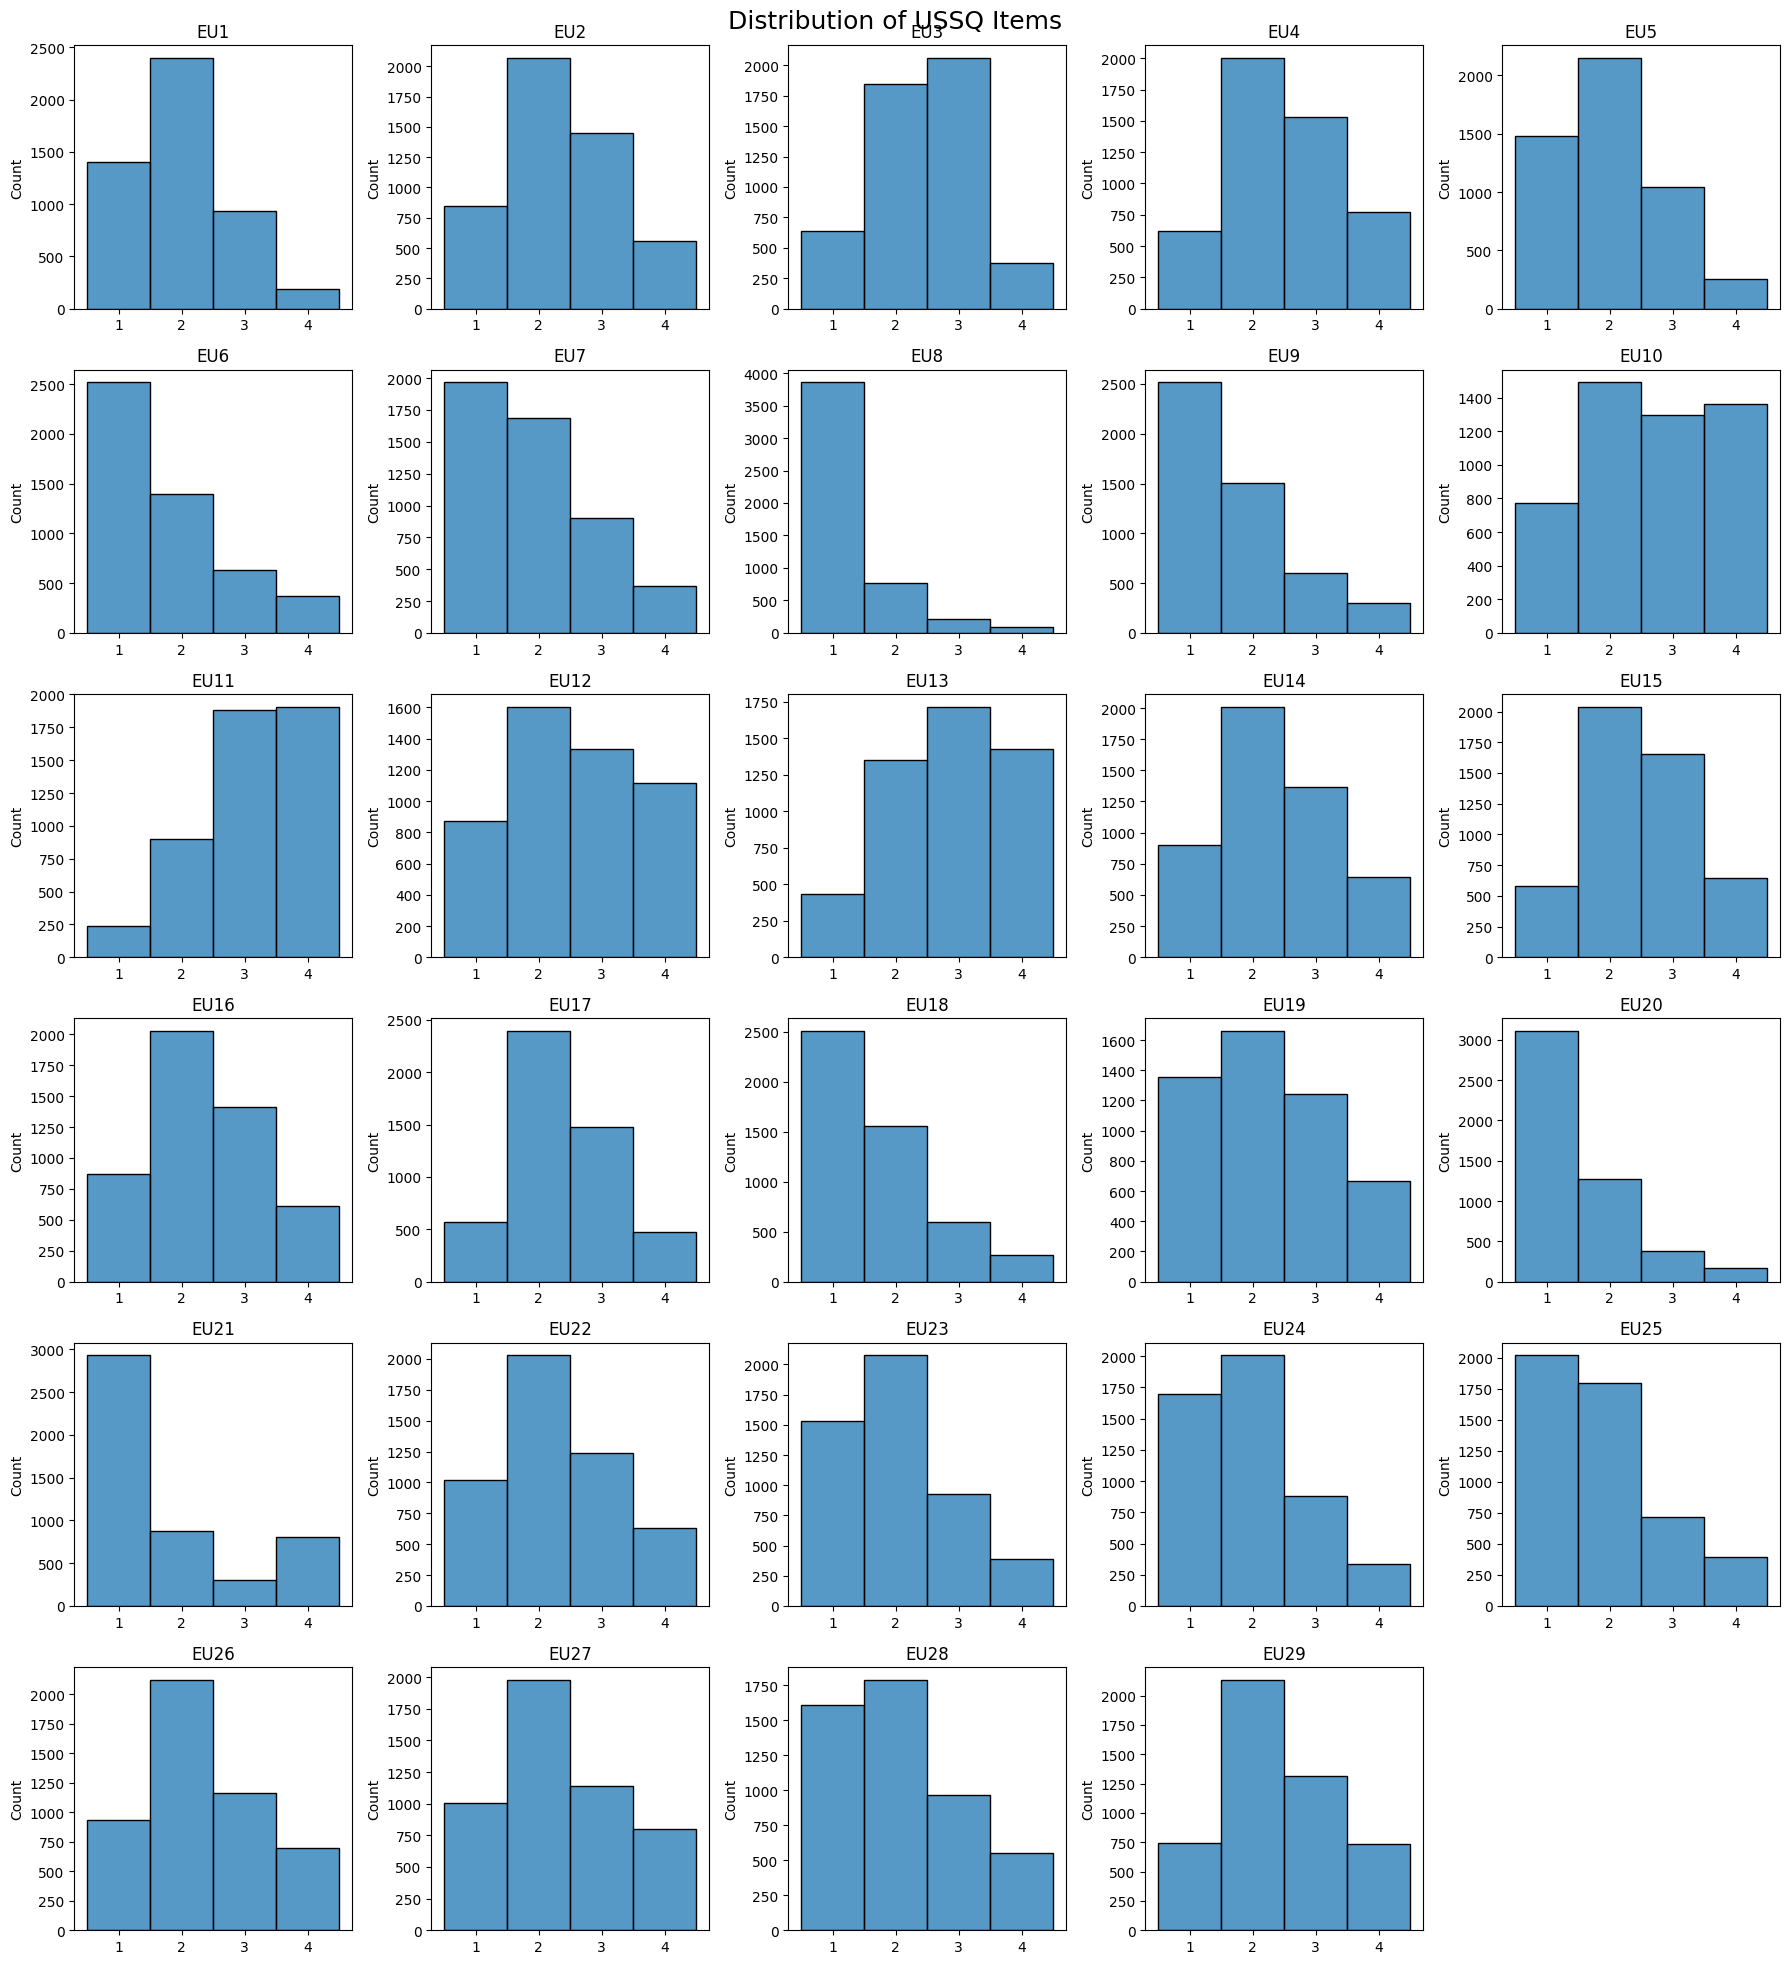

In [76]:
fig, axes = plt.subplots(
    6,
    5,
    figsize=(18, 20)
)

axes = axes.flatten()

for i, col in enumerate(available_ussq):

    sns.histplot(
        df[col].dropna(),
        discrete=True,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

for j in range(
    len(available_ussq),
    len(axes)
):
    axes[j].axis("off")

plt.suptitle(
    "Distribution of USSQ Items",
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    "ussq_item_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 14. DASS statistics

In [77]:
if "DASS_S" in df.columns:

    dass_stats = df[
        [col for col in dass_columns if col in df.columns]
    ].describe().T

    display(dass_stats)

,count,mean,std,min,25%,50%,75%,max
DASS_D,4925.0,3.811980,4.158514,0.0,1.0,2.0,5.0,21.0
DASS_A,4925.0,4.378883,4.352908,0.0,1.0,3.0,7.0,21.0
DASS_S,4925.0,6.622944,4.924219,0.0,2.0,6.0,10.0,21.0
DASS_total,4925.0,29.627614,24.613870,0.0,10.0,24.0,44.0,126.0


# 15. DASS-S distribution

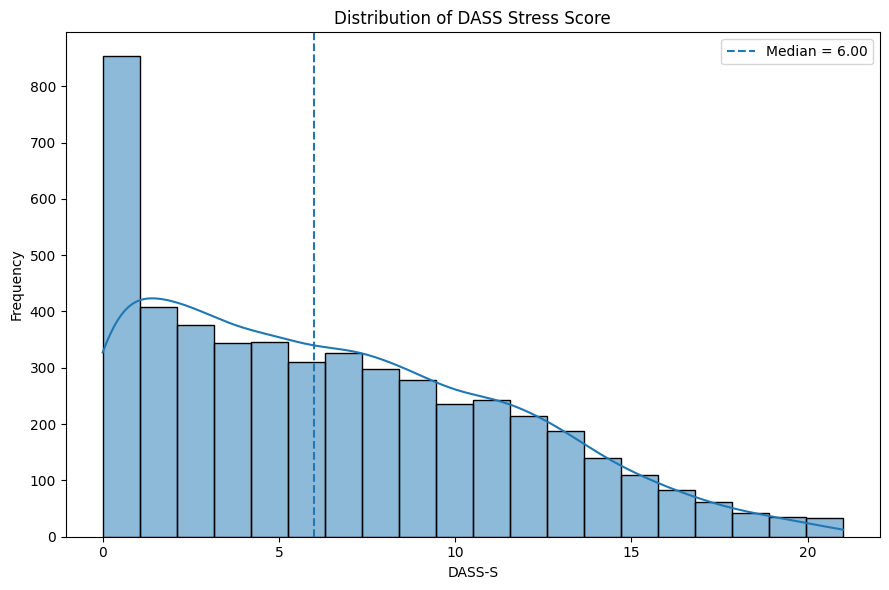

In [78]:
if "DASS_S" in df.columns:

    plt.figure(figsize=(9,6))

    sns.histplot(
        df["DASS_S"].dropna(),
        bins=20,
        kde=True
    )

    plt.axvline(
        df["DASS_S"].median(),
        linestyle="--",
        label=f"Median = {df['DASS_S'].median():.2f}"
    )

    plt.title("Distribution of DASS Stress Score")
    plt.xlabel("DASS-S")
    plt.ylabel("Frequency")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "dass_s_distribution.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# 16. Ryff PWB statistics

In [79]:
if len(ryff_columns) > 0:

    print("Ryff Psychological Well-Being statistics")

    display(
        df[ryff_columns].describe().T
    )

Ryff Psychological Well-Being statistics


,count,mean,std,min,25%,50%,75%,max
PWB_sel,4925.0,30.790660,7.504631,7.0,26.0,32.0,36.0,42.0
PWB_pos,4925.0,33.702741,7.547047,7.0,29.0,35.0,40.0,42.0
PWB_aut,4925.0,28.018883,6.537576,7.0,24.0,28.0,33.0,42.0
PWB_env,4925.0,29.769949,6.166824,7.0,25.0,30.0,34.0,42.0
PWB_pur,4925.0,33.328731,6.555313,7.0,29.0,34.0,39.0,42.0
PWB_per,4925.0,30.003046,7.151218,7.0,25.0,30.0,36.0,42.0


# 17. USSQ vs DASS-S correlations

In [80]:
if "DASS_S" in df.columns:

    ussq_dass_corr = (
        df[available_ussq + ["DASS_S"]]
        .corr()["DASS_S"]
        .drop("DASS_S")
        .sort_values(
            ascending=False
        )
    )

    print("USSQ item correlations with DASS-S")

    display(
        ussq_dass_corr.to_frame(
            "Correlation"
        )
    )

USSQ item correlations with DASS-S


,Correlation
EU12,0.464631
EU13,0.332425
EU10,0.330195
EU5,0.314063
EU9,0.306676
EU3,0.296421
EU4,0.292530
EU1,0.285116
EU20,0.280898
EU2,0.279719


# 18. Correlation visualization

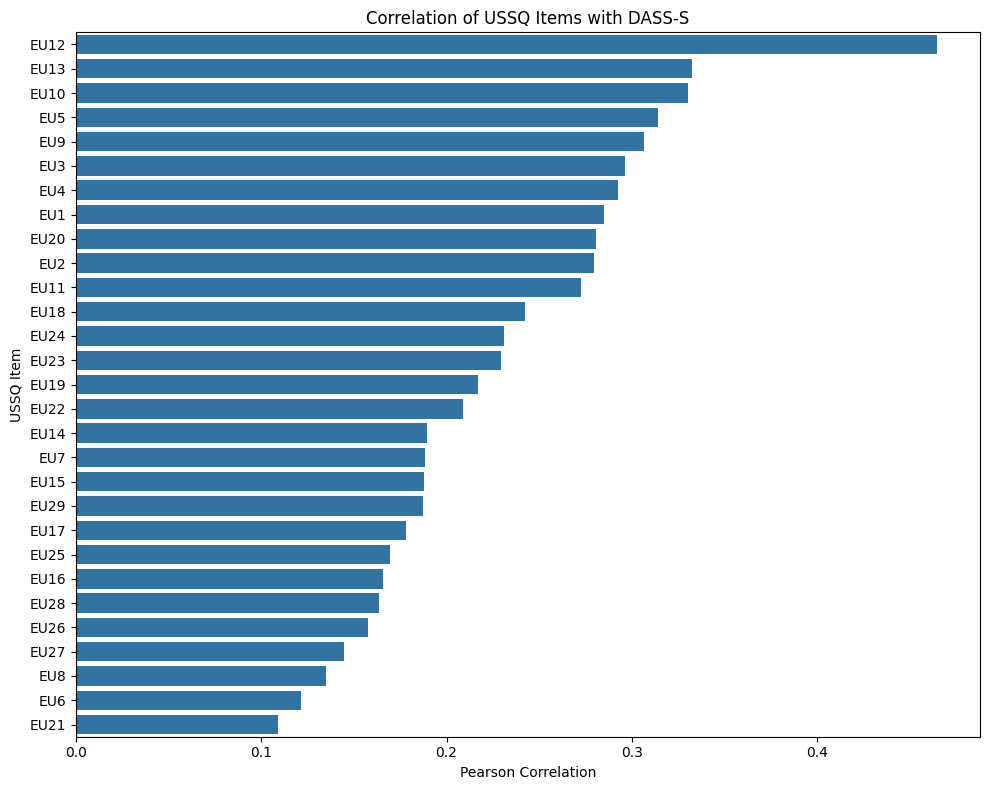

In [81]:
plt.figure(figsize=(10,8))

sns.barplot(
    x=ussq_dass_corr.values,
    y=ussq_dass_corr.index
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Correlation of USSQ Items with DASS-S"
)

plt.xlabel("Pearson Correlation")
plt.ylabel("USSQ Item")

plt.tight_layout()

plt.savefig(
    "ussq_dass_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 19. USSQ vs DASS + Ryff correlation matrix

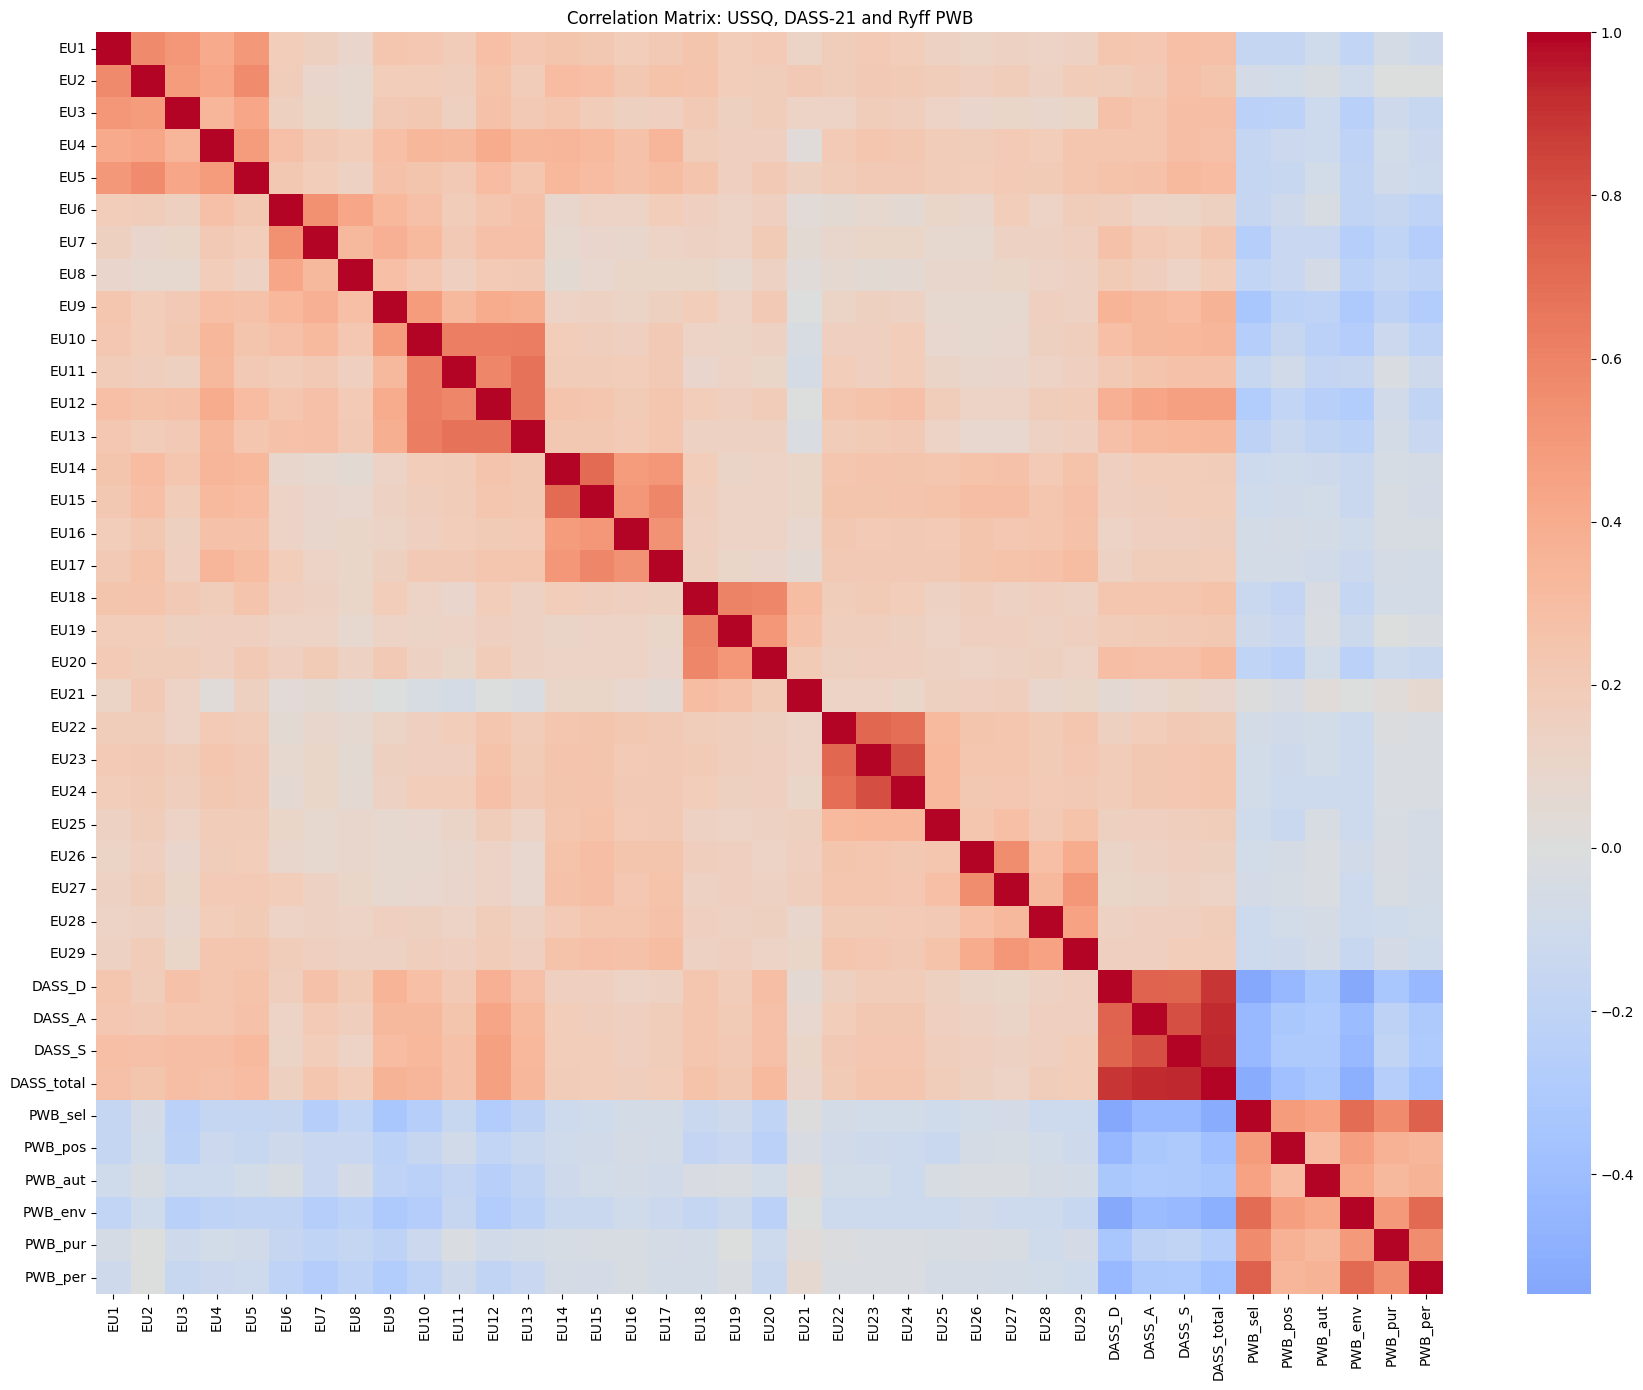

In [82]:
correlation_columns = (
    available_ussq
    + [col for col in dass_columns if col in df.columns]
    + ryff_columns
)

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(18,14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title(
    "Correlation Matrix: USSQ, DASS-21 and Ryff PWB"
)

plt.tight_layout()

plt.savefig(
    "ussq_dass_ryff_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 20. Explicit Ryff relationship analysis

In [83]:
if len(ryff_columns) > 0:

    ryff_corr = pd.DataFrame(
        index=available_ussq,
        columns=ryff_columns
    )

    for ussq in available_ussq:
        for pwb in ryff_columns:

            ryff_corr.loc[
                ussq,
                pwb
            ] = df[
                [ussq, pwb]
            ].corr().iloc[0,1]

    ryff_corr = ryff_corr.astype(float)

    display(
        ryff_corr
    )

,PWB_sel,PWB_pos,PWB_aut,PWB_env,PWB_pur,PWB_per
EU1,-0.169533,-0.168635,-0.097321,-0.183895,-0.061883,-0.104799
EU2,-0.069171,-0.081719,-0.040536,-0.096207,-0.006719,-0.002106
EU3,-0.229481,-0.217599,-0.114886,-0.240459,-0.104116,-0.153673
EU4,-0.160580,-0.127079,-0.113442,-0.205789,-0.078438,-0.125181
EU5,-0.163203,-0.153767,-0.086249,-0.193113,-0.091319,-0.112585
EU6,-0.159111,-0.104426,-0.043347,-0.191448,-0.157810,-0.202773
EU7,-0.257525,-0.144408,-0.143522,-0.258550,-0.197332,-0.264433
EU8,-0.181371,-0.142278,-0.068863,-0.221115,-0.164782,-0.207879
EU9,-0.328890,-0.215539,-0.203095,-0.310607,-0.212801,-0.283942
EU10,-0.257834,-0.157231,-0.231075,-0.265398,-0.128742,-0.203138


# 21. USSQ dimensions

In [84]:
dimension_map = {

    "Academic Overload": [
        "EU1", "EU2", "EU3", "EU4", "EU5"
    ],

    "Academic Inadequacy": [
        "EU6", "EU7", "EU8", "EU9"
    ],

    "Performance Pressure": [
        "EU10", "EU11", "EU12", "EU13", "EU14"
    ],

    "Social Relations": [
        "EU15", "EU16", "EU17", "EU18", "EU19"
    ],

    "Future Concerns": [
        "EU20", "EU21", "EU22", "EU23", "EU24"
    ],

    "Financial Stress": [
        "EU25", "EU26", "EU27", "EU28"
    ],

    "Institutional Environment": [
        "EU29"
    ]
}

for dimension, items in dimension_map.items():

    print(
        dimension,
        ":",
        len(items),
        "items"
    )

Academic Overload : 5 items
Academic Inadequacy : 4 items
Performance Pressure : 5 items
Social Relations : 5 items
Future Concerns : 5 items
Financial Stress : 4 items
Institutional Environment : 1 items


# 22. Create dimension scores


In [85]:
for dimension, items in dimension_map.items():

    valid_items = [
        item for item in items
        if item in df.columns
    ]

    df[
        f"DIM_{dimension.replace(' ', '_')}"
    ] = df[
        valid_items
    ].mean(axis=1)

dimension_columns = [
    f"DIM_{dimension.replace(' ', '_')}"
    for dimension in dimension_map
]

display(
    df[dimension_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
DIM_Academic_Overload,4925.0,2.257340,0.646714,1.0,1.80,2.2,2.8,4.0
DIM_Academic_Inadequacy,4925.0,1.682944,0.631060,1.0,1.25,1.5,2.0,4.0
DIM_Performance_Pressure,4925.0,2.701685,0.730216,1.0,2.20,2.8,3.2,4.0
DIM_Social_Relations,4925.0,2.236751,0.595738,1.0,1.80,2.2,2.6,4.0
DIM_Future_Concerns,4925.0,1.924102,0.627528,1.0,1.40,1.8,2.4,4.0
DIM_Financial_Stress,4925.0,2.168325,0.669613,1.0,1.75,2.0,2.5,4.0
DIM_Institutional_Environment,4925.0,2.413401,0.917197,1.0,2.00,2.0,3.0,4.0


# 23. Target leakage prevention


In [86]:
target = "DASS_S"

if target not in df.columns:
    raise ValueError(
        "DASS_S column was not found."
    )

# Only USSQ items + relevant demographics
candidate_features = (
    available_ussq
    + demographic_columns
)

# Explicitly remove all DASS variables
candidate_features = [
    col for col in candidate_features
    if not col.upper().startswith("DASS")
]

print("Predictor variables:")
print(candidate_features)

print("\nNumber of predictors:", len(candidate_features))

Predictor variables:
['EU1', 'EU2', 'EU3', 'EU4', 'EU5', 'EU6', 'EU7', 'EU8', 'EU9', 'EU10', 'EU11', 'EU12', 'EU13', 'EU14', 'EU15', 'EU16', 'EU17', 'EU18', 'EU19', 'EU20', 'EU21', 'EU22', 'EU23', 'EU24', 'EU25', 'EU26', 'EU27', 'EU28', 'EU29', 'sexo_bio', 'id_genero', 'edad', 'study_level', 'facultad']

Number of predictors: 34


# 23.1 Leakage check

In [87]:
leakage_candidates = [
    col for col in candidate_features
    if (
        "DASS" in col.upper()
        or "STRESS" in col.upper()
    )
]

print("Potential leakage variables:")
print(leakage_candidates)

if len(leakage_candidates) == 0:
    print(
        "✓ No DASS-derived target leakage detected."
    )
else:
    print(
        "WARNING: Potential leakage detected!"
    )

Potential leakage variables:
[]
✓ No DASS-derived target leakage detected.


# 24. Separate X and y

In [88]:
model_df = df[
    candidate_features + [target]
].copy()

model_df = model_df.dropna(
    subset=[target]
)

X = model_df[candidate_features]

y = model_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget statistics:")
display(y.describe())

X shape: (4925, 34)
y shape: (4925,)

Target statistics:


,DASS_S
count,4925.000000
mean,6.622944
std,4.924219
min,0.000000
25%,2.000000
50%,6.000000
75%,10.000000
max,21.000000


# 25. Identify numerical/categorical predictors

In [89]:
numeric_features = [
    col for col in candidate_features
    if pd.api.types.is_numeric_dtype(
        X[col]
    )
]

categorical_features = [
    col for col in candidate_features
    if col not in numeric_features
]

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['EU1', 'EU2', 'EU3', 'EU4', 'EU5', 'EU6', 'EU7', 'EU8', 'EU9', 'EU10', 'EU11', 'EU12', 'EU13', 'EU14', 'EU15', 'EU16', 'EU17', 'EU18', 'EU19', 'EU20', 'EU21', 'EU22', 'EU23', 'EU24', 'EU25', 'EU26', 'EU27', 'EU28', 'EU29', 'edad']

Categorical features:
['sexo_bio', 'id_genero', 'study_level', 'facultad']


# 26. Train/test split

In [90]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3940
Testing samples: 985


# 27. Preprocessing pipeline




In [91]:


# IDENTIFY FEATURE TYPES

numeric_features = [
    col
    for col in X.columns
    if pd.api.types.is_numeric_dtype(X[col])
]

categorical_features = [
    col
    for col in X.columns
    if col not in numeric_features
]


print("=" * 70)
print("FEATURE TYPES")
print("=" * 70)

print("\nNumerical features:")
print(f"Count: {len(numeric_features)}")
print(numeric_features)

print("\nCategorical features:")
print(f"Count: {len(categorical_features)}")
print(categorical_features)


#
# NUMERIC PIPELINE

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# CATEGORICAL PIPELINE

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# COMBINE BOTH PIPELINES

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


print("\n" + "=" * 70)
print("PREPROCESSING PIPELINE")
print("=" * 70)

print("Numeric pipeline:")
print("  - Median imputation")
print("  - StandardScaler")

print("\nCategorical pipeline:")
print("  - Most-frequent imputation")
print("  - One-hot encoding")

print("\nPreprocessor created successfully!")

FEATURE TYPES

Numerical features:
Count: 30
['EU1', 'EU2', 'EU3', 'EU4', 'EU5', 'EU6', 'EU7', 'EU8', 'EU9', 'EU10', 'EU11', 'EU12', 'EU13', 'EU14', 'EU15', 'EU16', 'EU17', 'EU18', 'EU19', 'EU20', 'EU21', 'EU22', 'EU23', 'EU24', 'EU25', 'EU26', 'EU27', 'EU28', 'EU29', 'edad']

Categorical features:
Count: 4
['sexo_bio', 'id_genero', 'study_level', 'facultad']

PREPROCESSING PIPELINE
Numeric pipeline:
  - Median imputation
  - StandardScaler

Categorical pipeline:
  - Most-frequent imputation
  - One-hot encoding

Preprocessor created successfully!


# 28. Define regression models

In [92]:

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge":
        Ridge(alpha=1.0),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=8,
            random_state=RANDOM_STATE
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=150,
            max_depth=4,
            learning_rate=0.05,
            random_state=RANDOM_STATE
        ),

    "XGBoost":
        XGBRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

    "CatBoost":
        CatBoostRegressor(
            iterations=200,
            depth=6,
            learning_rate=0.05,
            loss_function="RMSE",
            verbose=False,
            random_seed=RANDOM_STATE
        ),

    "LightGBM":
        LGBMRegressor(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            verbosity=-1
        ),

    "KNN":
        KNeighborsRegressor(
            n_neighbors=5
        ),

    "SVR":
        SVR(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
}

print("Models:", len(models))

Models: 10


# 29. Create model pipelines

In [93]:


pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

print("Pipelines created successfully.")

print("\nAvailable pipelines:")
for name in pipelines:
    print("-", name)

Pipelines created successfully.

Available pipelines:
- Linear Regression
- Ridge
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost
- CatBoost
- LightGBM
- KNN
- SVR


# 30. Train and evaluate all models

In [94]:
results = []

for name, pipeline in pipelines.items():

    print(
        f"\nTraining {name}..."
    )

    start_time = time.time()

    pipeline.fit(
        X_train,
        y_train
    )

    training_time = (
        time.time() - start_time
    )

    y_pred = pipeline.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    results.append({

        "Model": name,

        "MAE": mae,

        "RMSE": rmse,

        "R2": r2,

        "Training_Time": training_time
    })

results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    "RMSE"
)

display(
    results_df
)


Training Linear Regression...

Training Ridge...

Training Decision Tree...

Training Random Forest...

Training Gradient Boosting...

Training XGBoost...

Training CatBoost...

Training LightGBM...

Training KNN...

Training SVR...


,Model,MAE,RMSE,R2,Training_Time
0,Linear Regression,3.231432,4.060880,0.305929,0.055661
1,Ridge,3.231409,4.060981,0.305894,0.046166
5,XGBoost,3.215762,4.080984,0.299040,1.225180
6,CatBoost,3.244715,4.082879,0.298388,0.652411
3,Random Forest,3.291081,4.112127,0.288300,4.149449
9,SVR,3.239616,4.113480,0.287832,1.070515
4,Gradient Boosting,3.261078,4.120525,0.285390,1.880683
7,LightGBM,3.274507,4.148442,0.275674,0.309530
8,KNN,3.601015,4.547866,0.129479,0.024577
2,Decision Tree,3.727621,4.776363,0.039807,0.072975


# 31. 5-fold cross-validation

In [95]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, pipeline in pipelines.items():

    print(
        f"Cross-validating {name}..."
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({

        "Model": name,

        "CV_MAE_Mean":
            -scores["test_MAE"].mean(),

        "CV_MAE_STD":
            scores["test_MAE"].std(),

        "CV_RMSE_Mean":
            -scores["test_RMSE"].mean(),

        "CV_RMSE_STD":
            scores["test_RMSE"].std(),

        "CV_R2_Mean":
            scores["test_R2"].mean(),

        "CV_R2_STD":
            scores["test_R2"].std()
    })

cv_df = pd.DataFrame(
    cv_results
)

cv_df = cv_df.sort_values(
    "CV_RMSE_Mean"
)

display(cv_df)

Cross-validating Linear Regression...
Cross-validating Ridge...
Cross-validating Decision Tree...
Cross-validating Random Forest...
Cross-validating Gradient Boosting...
Cross-validating XGBoost...
Cross-validating CatBoost...
Cross-validating LightGBM...
Cross-validating KNN...
Cross-validating SVR...


,Model,CV_MAE_Mean,CV_MAE_STD,CV_RMSE_Mean,CV_RMSE_STD,CV_R2_Mean,CV_R2_STD
1,Ridge,3.240605,0.027608,4.062396,0.051936,0.316532,0.034553
0,Linear Regression,3.240738,0.027473,4.062546,0.051865,0.316483,0.034512
6,CatBoost,3.248780,0.046764,4.064093,0.071699,0.315809,0.039171
4,Gradient Boosting,3.269623,0.038787,4.083748,0.063320,0.309260,0.037137
5,XGBoost,3.265342,0.051460,4.086937,0.067329,0.308316,0.035077
7,LightGBM,3.291546,0.040219,4.119485,0.059007,0.297018,0.039276
3,Random Forest,3.314683,0.051949,4.138904,0.071751,0.290829,0.031646
9,SVR,3.276178,0.050502,4.141195,0.068087,0.289200,0.047432
8,KNN,3.564832,0.085509,4.484912,0.111705,0.166973,0.048333
2,Decision Tree,3.650081,0.056171,4.664243,0.081476,0.099164,0.044657


# 32. Combined results

In [96]:
final_results = results_df.merge(
    cv_df,
    on="Model"
)

final_results = final_results.sort_values(
    "CV_RMSE_Mean"
)

display(final_results)

,Model,MAE,RMSE,R2,Training_Time,CV_MAE_Mean,CV_MAE_STD,CV_RMSE_Mean,CV_RMSE_STD,CV_R2_Mean,CV_R2_STD
1,Ridge,3.231409,4.060981,0.305894,0.046166,3.240605,0.027608,4.062396,0.051936,0.316532,0.034553
0,Linear Regression,3.231432,4.060880,0.305929,0.055661,3.240738,0.027473,4.062546,0.051865,0.316483,0.034512
3,CatBoost,3.244715,4.082879,0.298388,0.652411,3.248780,0.046764,4.064093,0.071699,0.315809,0.039171
6,Gradient Boosting,3.261078,4.120525,0.285390,1.880683,3.269623,0.038787,4.083748,0.063320,0.309260,0.037137
2,XGBoost,3.215762,4.080984,0.299040,1.225180,3.265342,0.051460,4.086937,0.067329,0.308316,0.035077
7,LightGBM,3.274507,4.148442,0.275674,0.309530,3.291546,0.040219,4.119485,0.059007,0.297018,0.039276
4,Random Forest,3.291081,4.112127,0.288300,4.149449,3.314683,0.051949,4.138904,0.071751,0.290829,0.031646
5,SVR,3.239616,4.113480,0.287832,1.070515,3.276178,0.050502,4.141195,0.068087,0.289200,0.047432
8,KNN,3.601015,4.547866,0.129479,0.024577,3.564832,0.085509,4.484912,0.111705,0.166973,0.048333
9,Decision Tree,3.727621,4.776363,0.039807,0.072975,3.650081,0.056171,4.664243,0.081476,0.099164,0.044657


# 33. Model comparison visualization

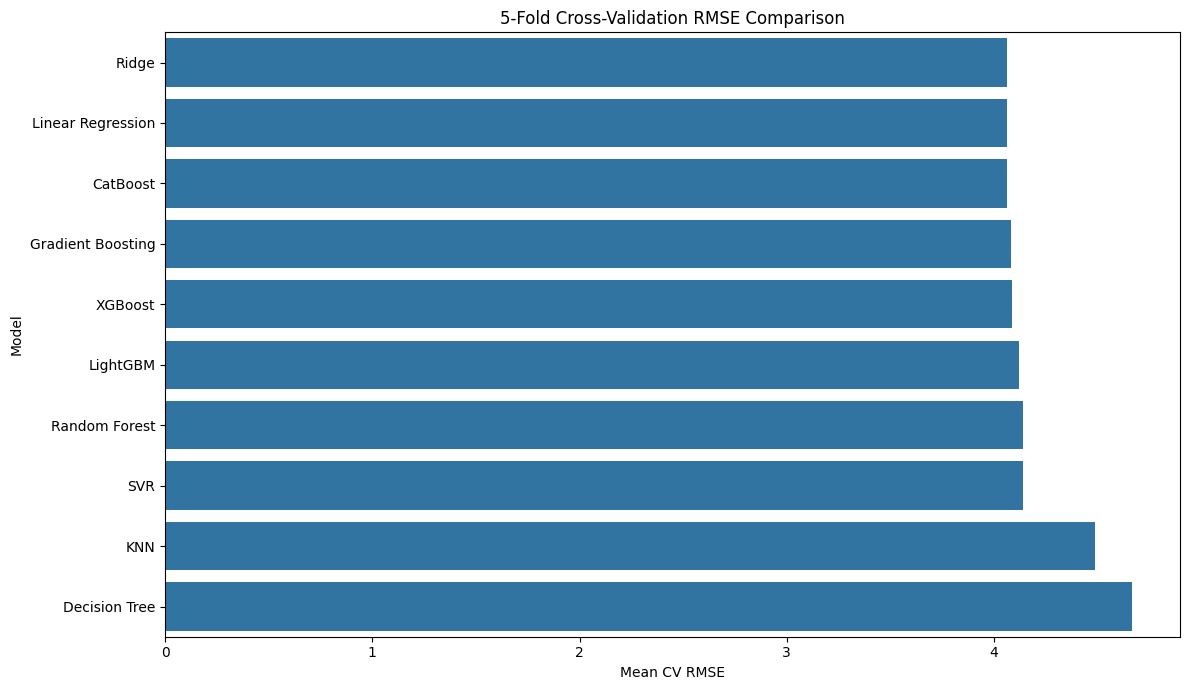

In [97]:
plt.figure(figsize=(12,7))

sns.barplot(
    data=final_results,
    x="CV_RMSE_Mean",
    y="Model"
)

plt.title(
    "5-Fold Cross-Validation RMSE Comparison"
)

plt.xlabel(
    "Mean CV RMSE"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()

plt.savefig(
    "model_cv_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 34. R² comparison

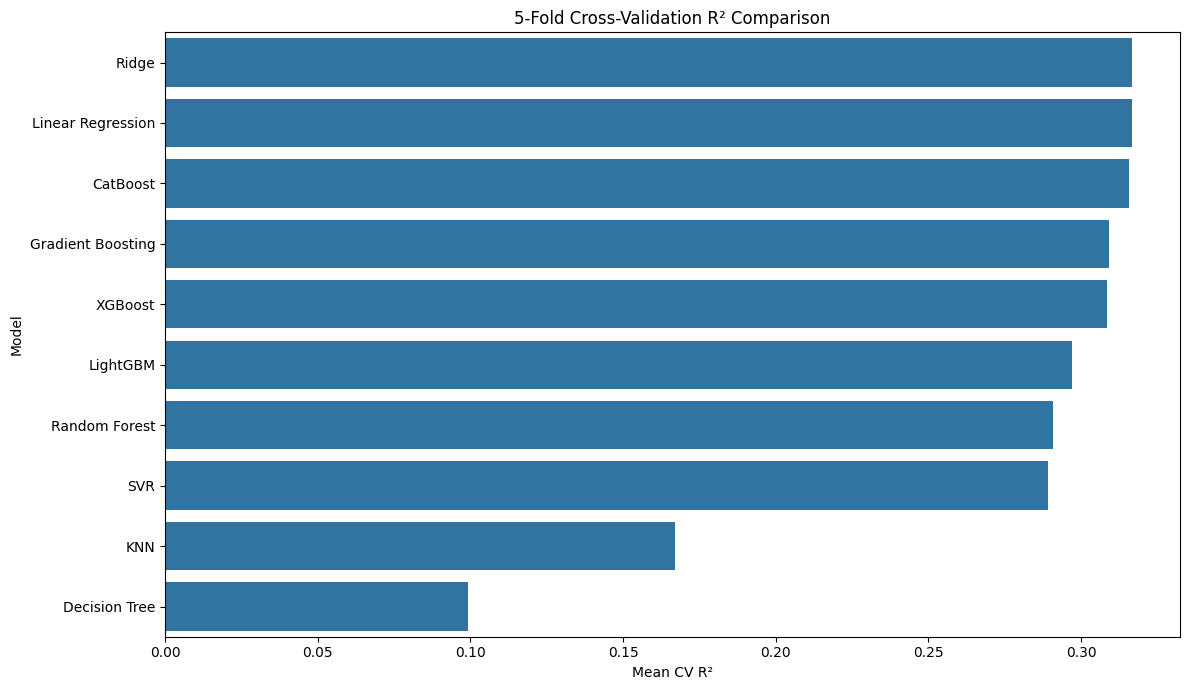

In [98]:
plt.figure(figsize=(12,7))

sns.barplot(
    data=final_results,
    x="CV_R2_Mean",
    y="Model"
)

plt.title(
    "5-Fold Cross-Validation R² Comparison"
)

plt.xlabel(
    "Mean CV R²"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()

plt.savefig(
    "model_cv_r2_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 35. Select best model

In [99]:
best_model_name = (
    final_results
    .iloc[0]["Model"]
)

best_pipeline = pipelines[
    best_model_name
]

print(
    "Best model:",
    best_model_name
)

Best model: Ridge


# 36. Best model prediction analysis

In [100]:
best_pipeline.fit(
    X_train,
    y_train
)

best_pred = best_pipeline.predict(
    X_test
)

best_mae = mean_absolute_error(
    y_test,
    best_pred
)

best_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        best_pred
    )
)

best_r2 = r2_score(
    y_test,
    best_pred
)

print(
    "Best Model:",
    best_model_name
)

print(
    f"MAE: {best_mae:.4f}"
)

print(
    f"RMSE: {best_rmse:.4f}"
)

print(
    f"R²: {best_r2:.4f}"
)

Best Model: Ridge
MAE: 3.2314
RMSE: 4.0610
R²: 0.3059


# 37. Actual vs predicted

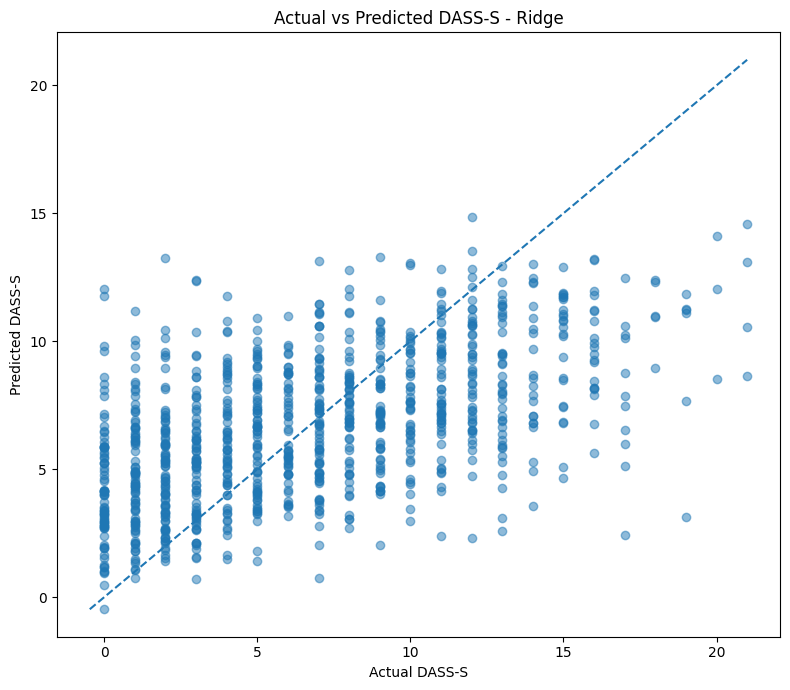

In [101]:
plt.figure(figsize=(8,7))

plt.scatter(
    y_test,
    best_pred,
    alpha=0.5
)

min_value = min(
    y_test.min(),
    best_pred.min()
)

max_value = max(
    y_test.max(),
    best_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual DASS-S"
)

plt.ylabel(
    "Predicted DASS-S"
)

plt.title(
    f"Actual vs Predicted DASS-S - {best_model_name}"
)

plt.tight_layout()

plt.savefig(
    "actual_vs_predicted_dass_s.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 38. Residual analysis


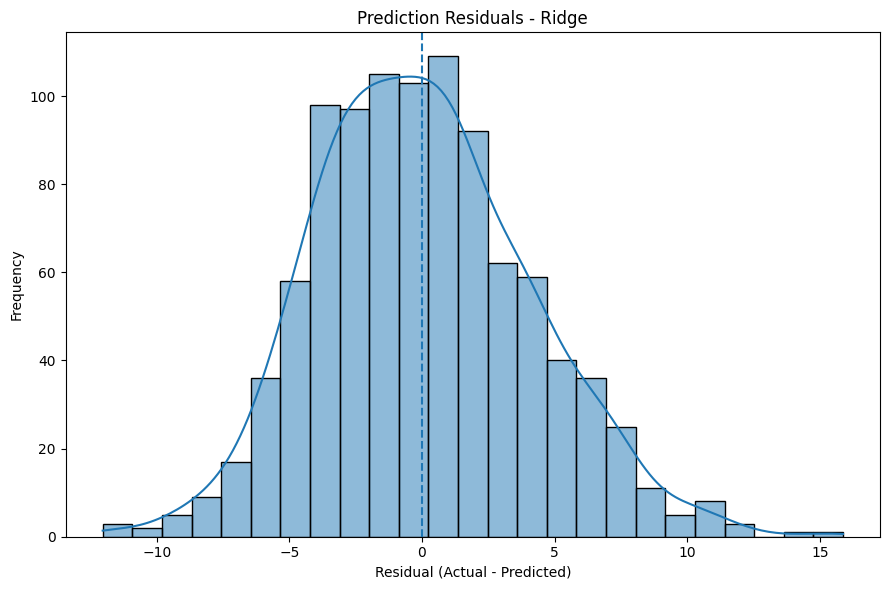

In [102]:
residuals = y_test - best_pred

plt.figure(figsize=(9,6))

sns.histplot(
    residuals,
    bins=25,
    kde=True
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    f"Prediction Residuals - {best_model_name}"
)

plt.xlabel(
    "Residual (Actual - Predicted)"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()

plt.savefig(
    "residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 39. SHAP preparation

In [103]:
tree_models = [
    "Random Forest",
    "Decision Tree",
    "Gradient Boosting",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]

if best_model_name in tree_models:

    shap_model_name = best_model_name

else:

    # Select best tree model by CV RMSE
    tree_results = final_results[
        final_results["Model"].isin(
            tree_models
        )
    ]

    shap_model_name = (
        tree_results
        .sort_values(
            "CV_RMSE_Mean"
        )
        .iloc[0]["Model"]
    )

print(
    "Model selected for SHAP:",
    shap_model_name
)

Model selected for SHAP: CatBoost


# 40. Transform data for SHAP

In [104]:
shap_pipeline = pipelines[
    shap_model_name
]

shap_pipeline.fit(
    X_train,
    y_train
)

preprocessor_fitted = (
    shap_pipeline
    .named_steps["preprocessor"]
)

tree_model = (
    shap_pipeline
    .named_steps["model"]
)

X_train_transformed = (
    preprocessor_fitted
    .transform(X_train)
)

X_test_transformed = (
    preprocessor_fitted
    .transform(X_test)
)

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print(
    "Transformed feature count:",
    len(feature_names)
)

Transformed feature count: 45


#41. SHAP analysis

In [105]:
explainer = shap.TreeExplainer(
    tree_model
)

# Use a manageable sample
sample_size = min(
    1000,
    len(X_test_shap)
)

X_shap_sample = (
    X_test_shap
    .sample(
        sample_size,
        random_state=RANDOM_STATE
    )
)

shap_values = explainer(
    X_shap_sample
)

print(
    "SHAP analysis completed."
)

SHAP analysis completed.


# 42. SHAP summary plot

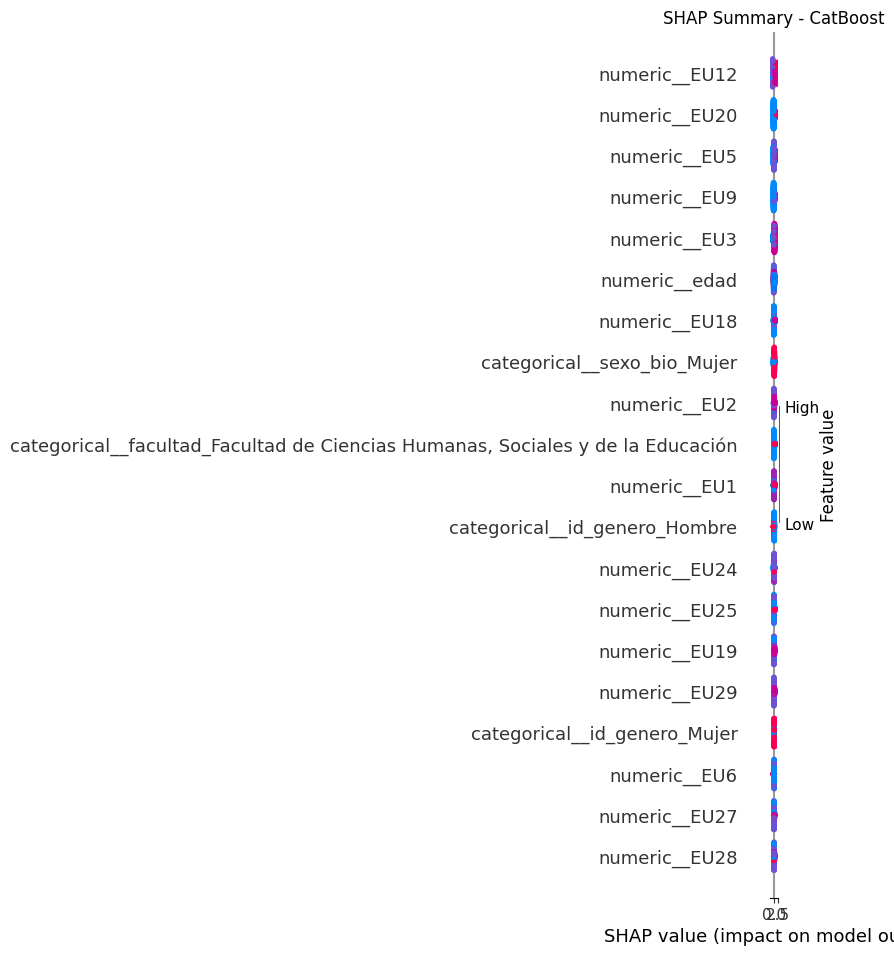

In [106]:
plt.figure()

shap.summary_plot(
    shap_values.values,
    X_shap_sample,
    show=False
)

plt.title(
    f"SHAP Summary - {shap_model_name}"
)

plt.tight_layout()

plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 43. SHAP feature importance

In [107]:
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({

    "Feature":
        X_shap_sample.columns,

    "Mean_Absolute_SHAP":
        mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
)

display(
    shap_importance.head(20)
)

,Feature,Mean_Absolute_SHAP
11,numeric__EU12,1.223000
19,numeric__EU20,0.385406
4,numeric__EU5,0.302198
8,numeric__EU9,0.296936
2,numeric__EU3,0.284572
29,numeric__edad,0.192102
17,numeric__EU18,0.184648
31,categorical__sexo_bio_Mujer,0.167031
1,numeric__EU2,0.153664
42,categorical__facultad_Facultad de Ciencias Hum...,0.152125


# 44. Remove preprocessing prefixes

In [108]:
def clean_feature_name(feature):

    feature = feature.replace(
        "numeric__",
        ""
    )

    feature = feature.replace(
        "categorical__",
        ""
    )

    return feature


shap_importance[
    "Clean_Feature"
] = shap_importance[
    "Feature"
].apply(
    clean_feature_name
)

display(
    shap_importance.head(20)
)

,Feature,Mean_Absolute_SHAP,Clean_Feature
11,numeric__EU12,1.223000,EU12
19,numeric__EU20,0.385406,EU20
4,numeric__EU5,0.302198,EU5
8,numeric__EU9,0.296936,EU9
2,numeric__EU3,0.284572,EU3
29,numeric__edad,0.192102,edad
17,numeric__EU18,0.184648,EU18
31,categorical__sexo_bio_Mujer,0.167031,sexo_bio_Mujer
1,numeric__EU2,0.153664,EU2
42,categorical__facultad_Facultad de Ciencias Hum...,0.152125,"facultad_Facultad de Ciencias Humanas, Sociale..."


# 45. USSQ-only SHAP ranking

In [109]:
ussq_shap = shap_importance[
    shap_importance[
        "Clean_Feature"
    ].isin(
        available_ussq
    )
].copy()

ussq_shap = ussq_shap.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

ussq_shap[
    "Rank"
] = range(
    1,
    len(ussq_shap) + 1
)

display(
    ussq_shap.head(15)
)

,Feature,Mean_Absolute_SHAP,Clean_Feature,Rank
11,numeric__EU12,1.223000,EU12,1
19,numeric__EU20,0.385406,EU20,2
4,numeric__EU5,0.302198,EU5,3
8,numeric__EU9,0.296936,EU9,4
2,numeric__EU3,0.284572,EU3,5
17,numeric__EU18,0.184648,EU18,6
1,numeric__EU2,0.153664,EU2,7
0,numeric__EU1,0.151814,EU1,8
23,numeric__EU24,0.132619,EU24,9
24,numeric__EU25,0.118343,EU25,10


# 46. Top USSQ SHAP plot

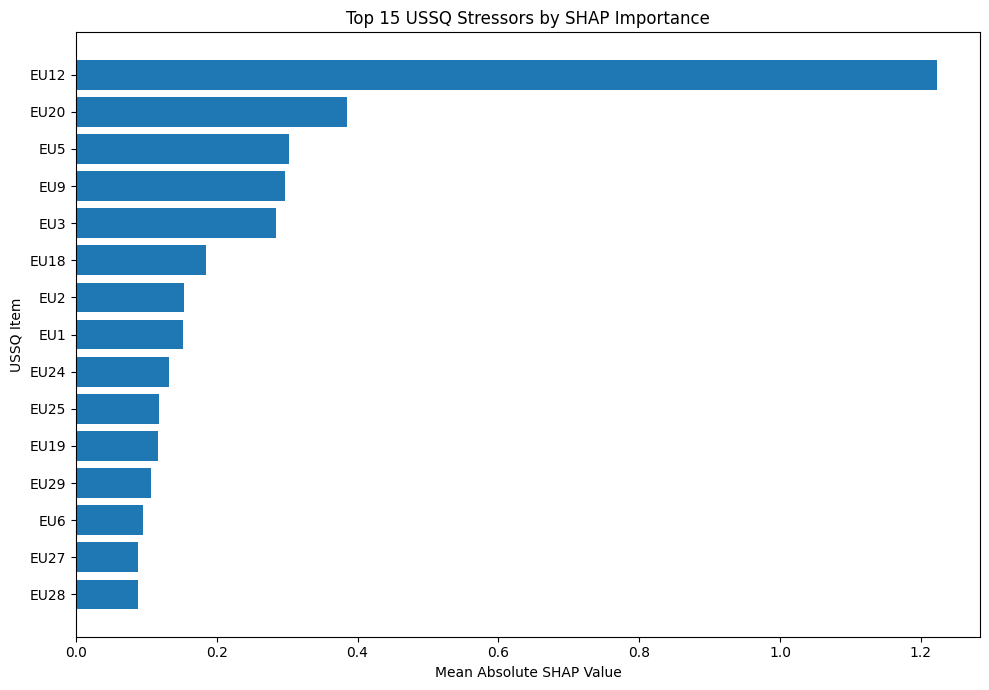

In [110]:
top_n = 15

top_ussq = (
    ussq_shap
    .head(top_n)
    .sort_values(
        "Mean_Absolute_SHAP"
    )
)

plt.figure(figsize=(10,7))

plt.barh(
    top_ussq["Clean_Feature"],
    top_ussq["Mean_Absolute_SHAP"]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "USSQ Item"
)

plt.title(
    f"Top {top_n} USSQ Stressors by SHAP Importance"
)

plt.tight_layout()

plt.savefig(
    "shap_ussq_top15.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 47. Dimension-level SHAP analysis

In [111]:
dimension_shap = []

for dimension, items in dimension_map.items():

    available_items = [
        item
        for item in items
        if item in ussq_shap[
            "Clean_Feature"
        ].values
    ]

    importance = ussq_shap[
        ussq_shap[
            "Clean_Feature"
        ].isin(
            available_items
        )
    ][
        "Mean_Absolute_SHAP"
    ].sum()

    dimension_shap.append({

        "Dimension":
            dimension,

        "SHAP_Importance":
            importance
    })

dimension_shap_df = pd.DataFrame(
    dimension_shap
)

dimension_shap_df[
    "Percentage"
] = (
    dimension_shap_df[
        "SHAP_Importance"
    ]
    /
    dimension_shap_df[
        "SHAP_Importance"
    ].sum()
    * 100
)

dimension_shap_df = (
    dimension_shap_df
    .sort_values(
        "SHAP_Importance",
        ascending=False
    )
)

display(
    dimension_shap_df
)

,Dimension,SHAP_Importance,Percentage
2,Performance Pressure,1.458714,32.395783
0,Academic Overload,0.957989,21.275455
4,Future Concerns,0.694082,15.414500
1,Academic Inadequacy,0.523694,11.630443
3,Social Relations,0.402576,8.940600
5,Financial Stress,0.359078,7.974571
6,Institutional Environment,0.106655,2.368649


# 48. Dimension SHAP plot


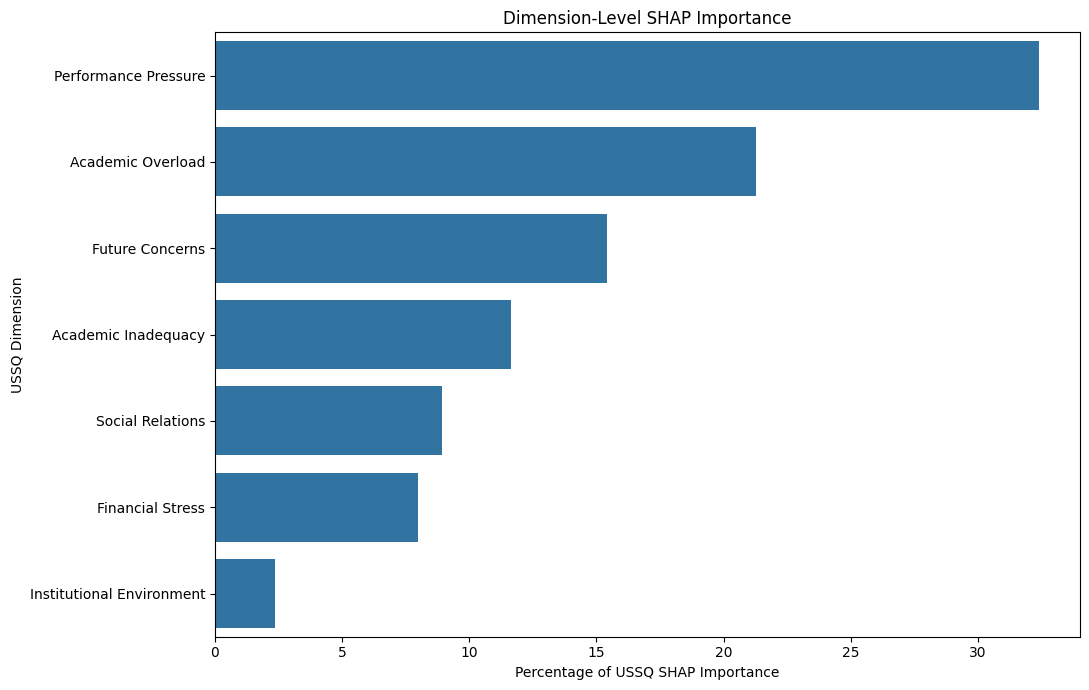

In [112]:
plt.figure(figsize=(11,7))

sns.barplot(
    data=dimension_shap_df,
    x="Percentage",
    y="Dimension"
)

plt.xlabel(
    "Percentage of USSQ SHAP Importance"
)

plt.ylabel(
    "USSQ Dimension"
)

plt.title(
    "Dimension-Level SHAP Importance"
)

plt.tight_layout()

plt.savefig(
    "dimension_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 49. Feature importance vs correlation

In [113]:
comparison = ussq_shap[
    [
        "Clean_Feature",
        "Mean_Absolute_SHAP"
    ]
].copy()

comparison = comparison.rename(
    columns={
        "Clean_Feature": "Feature"
    }
)

comparison["Correlation"] = (
    comparison["Feature"]
    .map(
        ussq_dass_corr
    )
)

display(
    comparison.sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    ).head(15)
)

,Feature,Mean_Absolute_SHAP,Correlation
11,EU12,1.223000,0.464631
19,EU20,0.385406,0.280898
4,EU5,0.302198,0.314063
8,EU9,0.296936,0.306676
2,EU3,0.284572,0.296421
17,EU18,0.184648,0.242383
1,EU2,0.153664,0.279719
0,EU1,0.151814,0.285116
23,EU24,0.132619,0.231169
24,EU25,0.118343,0.169263


# 50. Secondary binary classification

In [114]:
classification_df = model_df.copy()

median_stress = classification_df[
    "DASS_S"
].median()

classification_df[
    "Stress_Class"
] = (
    classification_df[
        "DASS_S"
    ] >= median_stress
).astype(int)

print(
    "Median DASS-S:",
    median_stress
)

print("\nClass distribution:")

display(
    classification_df[
        "Stress_Class"
    ].value_counts(
        normalize=True
    )
    .mul(100)
    .round(2)
)

Median DASS-S: 6.0

Class distribution:


,proportion
Stress_Class,
1,52.75
0,47.25


# 51. Classification split

In [115]:
X_cls = classification_df[
    candidate_features
]

y_cls = classification_df[
    "Stress_Class"
]

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    stratify=y_cls,
    random_state=RANDOM_STATE
)

#52. Classification model comparison

In [116]:
classification_models = {

    "Logistic Regression":
        __import__(
            "sklearn.linear_model",
            fromlist=["LogisticRegression"]
        ).LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

    "Gradient Boosting":
        __import__(
            "sklearn.ensemble",
            fromlist=["GradientBoostingClassifier"]
        ).GradientBoostingClassifier(
            n_estimators=150,
            max_depth=4,
            random_state=RANDOM_STATE
        ),

    "XGBoost":
        __import__(
            "xgboost",
            fromlist=["XGBClassifier"]
        ).XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            eval_metric="logloss"
        ),

    "CatBoost":
        __import__(
            "catboost",
            fromlist=["CatBoostClassifier"]
        ).CatBoostClassifier(
            iterations=200,
            depth=6,
            learning_rate=0.05,
            verbose=False,
            random_seed=RANDOM_STATE
        ),

    "LightGBM":
        __import__(
            "lightgbm",
            fromlist=["LGBMClassifier"]
        ).LGBMClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            verbosity=-1
        ),

    "SVM":
        __import__(
            "sklearn.svm",
            fromlist=["SVC"]
        ).SVC(
            probability=True,
            random_state=RANDOM_STATE
        ),

    "KNN":
        __import__(
            "sklearn.neighbors",
            fromlist=["KNeighborsClassifier"]
        ).KNeighborsClassifier(
            n_neighbors=5
        ),

    "Decision Tree":
        __import__(
            "sklearn.tree",
            fromlist=["DecisionTreeClassifier"]
        ).DecisionTreeClassifier(
            max_depth=10,
            random_state=RANDOM_STATE
        )
}

#53. Classification evaluation

In [117]:
classification_results = []

for name, model in classification_models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    start_time = time.time()

    pipeline.fit(
        X_train_cls,
        y_train_cls
    )

    training_time = (
        time.time() - start_time
    )

    predictions = pipeline.predict(
        X_test_cls
    )

    probabilities = pipeline.predict_proba(
        X_test_cls
    )[:, 1]

    cm = confusion_matrix(
        y_test_cls,
        predictions
    )

    tn, fp, fn, tp = cm.ravel()

    classification_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_test_cls,
                predictions
            ),

        "Precision":
            precision_score(
                y_test_cls,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test_cls,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test_cls,
                predictions,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_test_cls,
                probabilities
            ),

        "True Negatives": tn,

        "False Positives": fp,

        "False Negatives": fn,

        "True Positives": tp,

        "Training_Time":
            training_time
    })

classification_results_df = pd.DataFrame(
    classification_results
).sort_values(
    "F1",
    ascending=False
)

display(
    classification_results_df
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,True Negatives,False Positives,False Negatives,True Positives,Training_Time
0,Logistic Regression,0.700508,0.717602,0.713462,0.715526,0.762002,319,146,149,371,0.065704
4,CatBoost,0.696447,0.712909,0.711538,0.712223,0.762581,316,149,150,370,0.589763
6,SVM,0.688325,0.704415,0.705769,0.705091,0.755364,311,154,153,367,6.928458
1,Random Forest,0.684264,0.703704,0.694231,0.698935,0.753156,313,152,159,361,1.074924
2,Gradient Boosting,0.682234,0.703340,0.688462,0.695821,0.747184,314,151,162,358,1.795240
3,XGBoost,0.672081,0.692759,0.680769,0.686712,0.745703,308,157,166,354,0.223118
5,LightGBM,0.672081,0.693517,0.678846,0.686103,0.747229,309,156,167,353,0.224843
7,KNN,0.635533,0.657534,0.646154,0.651794,0.683040,290,175,184,336,0.024832
8,Decision Tree,0.630457,0.655378,0.632692,0.643836,0.657202,292,173,191,329,0.049923


#54. Classification confusion matrix

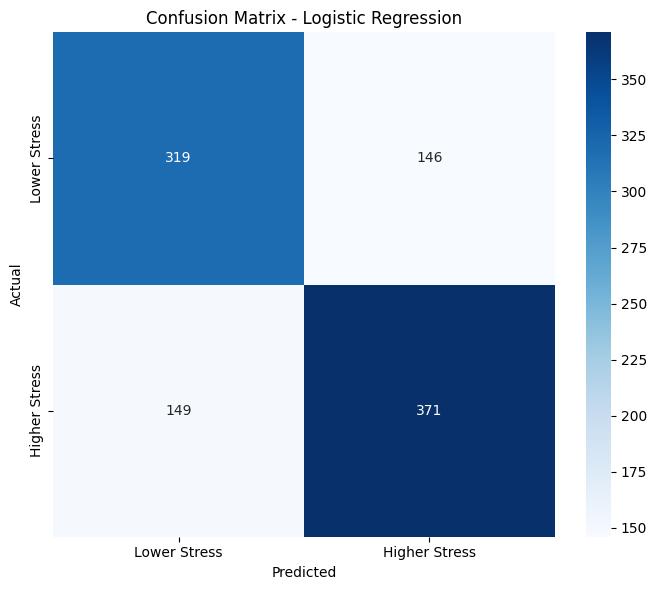

In [118]:
best_cls_name = (
    classification_results_df
    .iloc[0]["Model"]
)

best_cls_model = classification_models[
    best_cls_name
]

best_cls_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            best_cls_model
        )
    ]
)

best_cls_pipeline.fit(
    X_train_cls,
    y_train_cls
)

cls_predictions = (
    best_cls_pipeline
    .predict(X_test_cls)
)

cm = confusion_matrix(
    y_test_cls,
    cls_predictions
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Lower Stress",
        "Higher Stress"
    ],
    yticklabels=[
        "Lower Stress",
        "Higher Stress"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    f"Confusion Matrix - {best_cls_name}"
)

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#55. Subgroup analysis

In [119]:
def subgroup_regression_analysis(
    df_input,
    subgroup_column,
    min_size=100
):

    subgroup_results = []

    for group in df_input[
        subgroup_column
    ].dropna().unique():

        subset = df_input[
            df_input[
                subgroup_column
            ] == group
        ].copy()

        if len(subset) < min_size:
            continue

        X_sub = subset[
            candidate_features
        ]

        y_sub = subset[
            target
        ]

        X_sub_train, X_sub_test, \
        y_sub_train, y_sub_test = train_test_split(
            X_sub,
            y_sub,
            test_size=0.20,
            random_state=RANDOM_STATE
        )

        model = Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor
                ),
                (
                    "model",
                    models[
                        best_model_name
                    ]
                )
            ]
        )

        model.fit(
            X_sub_train,
            y_sub_train
        )

        predictions = model.predict(
            X_sub_test
        )

        subgroup_results.append({

            "Subgroup":
                str(group),

            "N":
                len(subset),

            "MAE":
                mean_absolute_error(
                    y_sub_test,
                    predictions
                ),

            "RMSE":
                np.sqrt(
                    mean_squared_error(
                        y_sub_test,
                        predictions
                    )
                ),

            "R2":
                r2_score(
                    y_sub_test,
                    predictions
                )
        })

    return pd.DataFrame(
        subgroup_results
    )

#56. Run subgroup analysis

In [120]:
if "study_level" in df.columns:

    study_level_results = (
        subgroup_regression_analysis(
            model_df,
            "study_level"
        )
    )

    print(
        "Study-level subgroup analysis"
    )

    display(
        study_level_results
    )

Study-level subgroup analysis


,Subgroup,N,MAE,RMSE,R2
0,undergraduate,4374,3.151323,3.939997,0.304395
1,postgraduate,551,3.451949,4.406159,0.386914


#57. Gender subgroup analysis

In [121]:
if "sexo_bio" in df.columns:

    sex_results = (
        subgroup_regression_analysis(
            model_df,
            "sexo_bio"
        )
    )

    print(
        "Biological-sex subgroup analysis"
    )

    display(
        sex_results
    )

Biological-sex subgroup analysis


,Subgroup,N,MAE,RMSE,R2
0,Mujer,2951,3.639593,4.399778,0.275078
1,Hombre,1964,2.930288,3.735631,0.277759


#58. Consistency of important USSQ items

In [122]:
top_items = (
    ussq_shap
    .head(10)
    [
        "Clean_Feature"
    ]
    .tolist()
)

consistency_table = comparison[
    comparison[
        "Feature"
    ].isin(
        top_items
    )
].copy()

consistency_table[
    "Abs_Correlation"
] = consistency_table[
    "Correlation"
].abs()

consistency_table = (
    consistency_table
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
)

display(
    consistency_table
)

,Feature,Mean_Absolute_SHAP,Correlation,Abs_Correlation
11,EU12,1.223000,0.464631,0.464631
19,EU20,0.385406,0.280898,0.280898
4,EU5,0.302198,0.314063,0.314063
8,EU9,0.296936,0.306676,0.306676
2,EU3,0.284572,0.296421,0.296421
17,EU18,0.184648,0.242383,0.242383
1,EU2,0.153664,0.279719,0.279719
0,EU1,0.151814,0.285116,0.285116
23,EU24,0.132619,0.231169,0.231169
24,EU25,0.118343,0.169263,0.169263


#59. Save all results

In [123]:
with pd.ExcelWriter(
    "USSQ_ML_Complete_Results.xlsx"
) as writer:

    results_df.to_excel(
        writer,
        sheet_name="Test_Results",
        index=False
    )

    cv_df.to_excel(
        writer,
        sheet_name="Cross_Validation",
        index=False
    )

    final_results.to_excel(
        writer,
        sheet_name="Combined_Results",
        index=False
    )

    ussq_shap.to_excel(
        writer,
        sheet_name="SHAP_USSQ",
        index=False
    )

    dimension_shap_df.to_excel(
        writer,
        sheet_name="Dimension_SHAP",
        index=False
    )

    classification_results_df.to_excel(
        writer,
        sheet_name="Classification",
        index=False
    )

    if "study_level" in df.columns:
        study_level_results.to_excel(
            writer,
            sheet_name="Study_Level",
            index=False
        )

    if "sexo_bio" in df.columns:
        sex_results.to_excel(
            writer,
            sheet_name="Sex_Subgroups",
            index=False
        )

print(
    "Results saved to USSQ_ML_Complete_Results.xlsx"
)

Results saved to USSQ_ML_Complete_Results.xlsx


#60. Final project summary

In [124]:
print("=" * 80)
print("FINAL PROJECT SUMMARY")
print("=" * 80)

print(
    f"Dataset size: {df.shape[0]} rows × {df.shape[1]} columns"
)

print(
    f"USSQ predictors: {len(available_ussq)}"
)

print(
    f"Target: {target}"
)

print(
    f"Best regression model: {best_model_name}"
)

print(
    f"Test MAE: {best_mae:.4f}"
)

print(
    f"Test RMSE: {best_rmse:.4f}"
)

print(
    f"Test R²: {best_r2:.4f}"
)

print(
    f"SHAP model: {shap_model_name}"
)

print(
    "\nTop 10 USSQ stressors:"
)

display(
    ussq_shap[
        [
            "Rank",
            "Clean_Feature",
            "Mean_Absolute_SHAP"
        ]
    ].head(10)
)

print(
    "\nTop USSQ dimensions:"
)

display(
    dimension_shap_df
)

print(
    "\nNo causal, diagnostic, or therapeutic interpretation "
    "should be made from these predictive results."
)

FINAL PROJECT SUMMARY
Dataset size: 4925 rows × 52 columns
USSQ predictors: 29
Target: DASS_S
Best regression model: Ridge
Test MAE: 3.2314
Test RMSE: 4.0610
Test R²: 0.3059
SHAP model: CatBoost

Top 10 USSQ stressors:


,Rank,Clean_Feature,Mean_Absolute_SHAP
11,1,EU12,1.223000
19,2,EU20,0.385406
4,3,EU5,0.302198
8,4,EU9,0.296936
2,5,EU3,0.284572
17,6,EU18,0.184648
1,7,EU2,0.153664
0,8,EU1,0.151814
23,9,EU24,0.132619
24,10,EU25,0.118343



Top USSQ dimensions:


,Dimension,SHAP_Importance,Percentage
2,Performance Pressure,1.458714,32.395783
0,Academic Overload,0.957989,21.275455
4,Future Concerns,0.694082,15.414500
1,Academic Inadequacy,0.523694,11.630443
3,Social Relations,0.402576,8.940600
5,Financial Stress,0.359078,7.974571
6,Institutional Environment,0.106655,2.368649



No causal, diagnostic, or therapeutic interpretation should be made from these predictive results.


\subsection{EDA Conclusion}
The current EDA examined the dataset structure, data quality, demographic characteristics, USSQ item response distributions, DASS-21 outcomes, Ryff Psychological Well-Being measures, and the correlations between USSQ items and DASS stress scores.

The analysis provides a current understanding of the dataset and the relationships among the variables. But, these exploratory correlations do not establish predictive performance or causal relationships by themselves. The next stage will focus on data preprocessing and baseline model development, including proper test split, handling of categorical variables when demographic features are included, implementation and comparison of baseline machine-learning models, and subsequent model explainability using SHAP.

In [125]:
ussq_means = (
    df[available_ussq]
    .mean()
    .sort_values(ascending=False)
)

display(
    ussq_means.to_frame("Mean Response")
)


,Mean Response
EU11,3.107208
EU13,2.839391
EU10,2.659492
EU12,2.546802
EU4,2.498477
EU15,2.480406
EU3,2.442843
EU29,2.413401
EU17,2.377056
EU16,2.357157
